<a href="https://colab.research.google.com/github/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA/blob/main/notebooks/00_comun/02_rejilla_2km.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 · Grilla común de celdas de 2 km

**Autor:** Daniel

**Propósito:** crear la grilla de celdas de 2 km × 2 km que comparten las cuatro partes, para llevar cada variable a la misma unidad espacial (sección 14.4 de la ruta de trabajo).

**Entradas:**
- `datos/comunes/altillanura_municipios.gpkg` (cuaderno 01, DVC).

**Salidas:**
- `datos/comunes/grilla_2km.gpkg`, capa `grilla` (DVC).
- `modulos/expansion/graficas/02_grilla_2km.png`.

**Método:**
- Celdas cuadradas de 2.000 m en EPSG:9377 (MAGNA-SIRGAS Origen Nacional), con las esquinas en múltiplos de 2.000 m. Así la grilla sale idéntica cada vez que se corre.
- Las celdas se recortan al borde exterior de la Altillanura: las del borde quedan más pequeñas y su área real está en `area_km2`.
- Cada celda pertenece a un solo municipio: el que ocupa la mayor parte de su área.

**Columnas de la grilla:**

| Columna | Qué es |
|---|---|
| `id_celda` | Llave de unión. Coordenadas en km de la esquina inferior izquierda de la celda, por ejemplo `x5120_y1986` |
| `mpio_cdpmp` | Código DIVIPOLA del municipio, como texto |
| `mpio_cnmbr` | Nombre del municipio |
| `area_km2` | Área de la celda dentro de la Altillanura (4 km² si está completa) |
| `frac_celda` | Fracción de la celda que está dentro de la Altillanura (1 si está completa) |
| `x_9377`, `y_9377` | Centroide de la celda en EPSG:9377, en metros |
| `geometry` | Polígono de la celda en EPSG:9377 |

## Paso 1. Rutas y librerías
- En **Colab** clona el repo en `/content/Proyecto-ALTILLANURA`.
- En **local** toma como raíz la carpeta del repo (dos niveles arriba del cuaderno).
- `traer(ruta)` baja de DVC un archivo pesado cuando hace falta.

In [13]:
import os, sys, subprocess
EN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA.git'

if EN_COLAB:
    RAIZ = '/content/Proyecto-ALTILLANURA'
    if not os.path.exists(RAIZ):
        subprocess.run(['git', 'clone', '-q', REPO, RAIZ], check=True)
else:
    RAIZ = os.path.abspath(os.path.join('..', '..'))

COMUNES = os.path.join(RAIZ, 'datos', 'comunes')
GRAFICAS = os.path.join(RAIZ, 'modulos', 'expansion', 'graficas')
os.makedirs(GRAFICAS, exist_ok=True)

def traer(ruta):
    if os.path.exists(os.path.join(RAIZ, ruta)):
        return
    if EN_COLAB:
        from google.colab import auth
        auth.authenticate_user()
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dvc[gs]'], check=True)
    subprocess.run([sys.executable, '-m', 'dvc', 'pull', '-q', ruta], cwd=RAIZ, check=True)
    print('Bajado de DVC:', ruta)

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

print('Raíz del repo:', RAIZ)

Raíz del repo: c:\Users\mipip\Downloads\altillanura_proyecto_\altillanura_proyecto


## Paso 2. Municipios y área de estudio
Los límites son los del cuaderno 01 (DANE, MGN 2025). El área total debe dar 135.649 km², la del acuerdo técnico.

In [14]:
traer('datos/comunes/altillanura_municipios.gpkg')

mpios = gpd.read_file(os.path.join(COMUNES, 'altillanura_municipios.gpkg')).to_crs(9377)
mpios['mpio_cdpmp'] = mpios['mpio_cdpmp'].astype(str).str.zfill(5)
mpios = mpios[['mpio_cdpmp', 'mpio_cnmbr', 'geometry']].sort_values('mpio_cdpmp').reset_index(drop=True)

area_estudio = shapely.union_all(mpios.geometry.values)
AREA_TOTAL_KM2 = area_estudio.area / 1e6

print(f'Municipios: {len(mpios)}')
print(f'Área total: {AREA_TOTAL_KM2:,.1f} km²')

Municipios: 7
Área total: 135,649.2 km²


## Paso 3. Celdas de 2 km
1. Se arma una malla de cuadrados de 2 km que cubre todo el rectángulo de la Altillanura y se dejan solo los que tocan el área de estudio.
2. Los cuadrados que caen completos dentro de un municipio se quedan tal cual.
3. Los que cruzan un límite (entre municipios o el borde exterior) se cortan con los municipios: la celda queda recortada al área de estudio y se asigna al municipio que tiene la mayor parte.

In [15]:
TAM = 2000

xmin, ymin, xmax, ymax = area_estudio.bounds
xs = np.arange(np.floor(xmin / TAM) * TAM, xmax, TAM)
ys = np.arange(np.floor(ymin / TAM) * TAM, ymax, TAM)
gx, gy = np.meshgrid(xs, ys)
gx, gy = gx.ravel(), gy.ravel()
cajas = shapely.box(gx, gy, gx + TAM, gy + TAM)

shapely.prepare(area_estudio)
toca = shapely.intersects(area_estudio, cajas)
cajas, gx, gy = cajas[toca], gx[toca], gy[toca]
ids = np.array([f'x{int(x) // 1000}_y{int(y) // 1000}' for x, y in zip(gx, gy)])

mpio_celda = np.full(len(cajas), '', dtype=object)
for cod, geom in zip(mpios['mpio_cdpmp'], mpios.geometry):
    shapely.prepare(geom)
    mpio_celda[shapely.contains_properly(geom, cajas)] = cod
completas = mpio_celda != ''

interior = gpd.GeoDataFrame({'id_celda': ids[completas], 'mpio_cdpmp': mpio_celda[completas]},
                            geometry=cajas[completas], crs=9377)

resto = gpd.GeoDataFrame({'id_celda': ids[~completas]}, geometry=cajas[~completas], crs=9377)
piezas = gpd.overlay(resto, mpios[['mpio_cdpmp', 'geometry']], how='intersection', keep_geom_type=True)
piezas['area_m2'] = piezas.area
piezas = piezas[piezas['area_m2'] > 0]
mayor = (piezas.sort_values('area_m2', ascending=False)
         .drop_duplicates('id_celda')[['id_celda', 'mpio_cdpmp']])
borde = piezas[['id_celda', 'geometry']].dissolve(by='id_celda').reset_index().merge(mayor, on='id_celda')

celdas = gpd.GeoDataFrame(pd.concat([interior, borde], ignore_index=True), geometry='geometry', crs=9377)
celdas = celdas.merge(mpios[['mpio_cdpmp', 'mpio_cnmbr']], on='mpio_cdpmp', how='left')
celdas['area_km2'] = celdas.area / 1e6
celdas['frac_celda'] = celdas['area_km2'] / (TAM / 1000) ** 2
centros = celdas.geometry.centroid
celdas['x_9377'] = centros.x.round(1)
celdas['y_9377'] = centros.y.round(1)
celdas = (celdas[['id_celda', 'mpio_cdpmp', 'mpio_cnmbr', 'area_km2', 'frac_celda', 'x_9377', 'y_9377', 'geometry']]
          .sort_values('id_celda').reset_index(drop=True))

print(f'Cuadrados que tocan la Altillanura: {len(cajas):,}')
print(f'Celdas completas dentro de un municipio: {len(interior):,}')
print(f'Celdas en un límite (recortadas o compartidas): {len(borde):,}')
print(f'Total de celdas: {len(celdas):,}')

Cuadrados que tocan la Altillanura: 34,763
Celdas completas dentro de un municipio: 32,259
Celdas en un límite (recortadas o compartidas): 2,504
Total de celdas: 34,763


## Paso 4. Verificación
- `id_celda` no se repite y todas las celdas tienen municipio.
- Las celdas no se montan entre sí: la suma de sus áreas es igual al área de estudio.
- Todas las geometrías son válidas y están en EPSG:9377.

En la tabla por municipio, el área de las celdas difiere un poco del área oficial porque cada celda de límite se cuenta entera en el municipio que tiene la mayor parte.

In [16]:
dif_area = abs(celdas['area_km2'].sum() - AREA_TOTAL_KM2) / AREA_TOTAL_KM2

assert celdas['id_celda'].is_unique
assert celdas['mpio_cdpmp'].notna().all() and (celdas['mpio_cdpmp'] != '').all()
assert celdas.is_valid.all()
assert celdas.crs.to_epsg() == 9377
assert dif_area < 1e-4

print(f'Suma del área de las celdas: {celdas["area_km2"].sum():,.1f} km² '
      f'| área de estudio: {AREA_TOTAL_KM2:,.1f} km² | diferencia: {dif_area:.6%}')

resumen = (celdas.groupby(['mpio_cdpmp', 'mpio_cnmbr'])
           .agg(celdas=('id_celda', 'size'),
                celdas_completas=('frac_celda', lambda s: int((s > 0.9999).sum())),
                area_celdas_km2=('area_km2', 'sum'))
           .reset_index())
resumen['area_oficial_km2'] = resumen['mpio_cdpmp'].map(mpios.set_index('mpio_cdpmp').area / 1e6)
resumen['dif_pct'] = (resumen['area_celdas_km2'] / resumen['area_oficial_km2'] - 1) * 100
print()
print(resumen.round(2).to_string(index=False))
print('\nVerificación OK')

Suma del área de las celdas: 135,649.2 km² | área de estudio: 135,649.2 km² | diferencia: 0.000000%

mpio_cdpmp     mpio_cnmbr  celdas  celdas_completas  area_celdas_km2  area_oficial_km2  dif_pct
     50325      MAPIRIPÁN    3129              2837         11921.52          11917.48     0.03
     50568  PUERTO GAITÁN    4394              4272         17329.11          17200.78     0.75
     50573   PUERTO LÓPEZ    1847              1601          6904.04           6898.24     0.08
     99001 PUERTO CARREÑO    3121              2937         12107.92          12142.32    -0.28
     99524   LA PRIMAVERA    4718              4549         18522.95          18492.11     0.17
     99624  SANTA ROSALÍA     940               889          3658.94           3679.01    -0.55
     99773       CUMARIBO   16614             15996         65204.75          65319.29    -0.18

Verificación OK


## Paso 5. Mapa de la grilla
A la izquierda, toda la Altillanura con las celdas coloreadas por municipio. A la derecha, una ventana de 30 × 30 km sobre el límite entre Puerto López y Puerto Gaitán, donde se ven las celdas de 2 km y cómo se asignan las del límite.

c:\Users\mipip\venv\Lib\site-packages\geopandas\plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)
c:\Users\mipip\venv\Lib\site-packages\geopandas\plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)
c:\Users\mipip\venv\Lib\site-packages\geopandas\plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)
c:\Users\mipip\venv\Lib\site-packages\geopandas\plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)
c:\Users\mipip\venv\Lib\site-packages\geopandas\plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_datafram

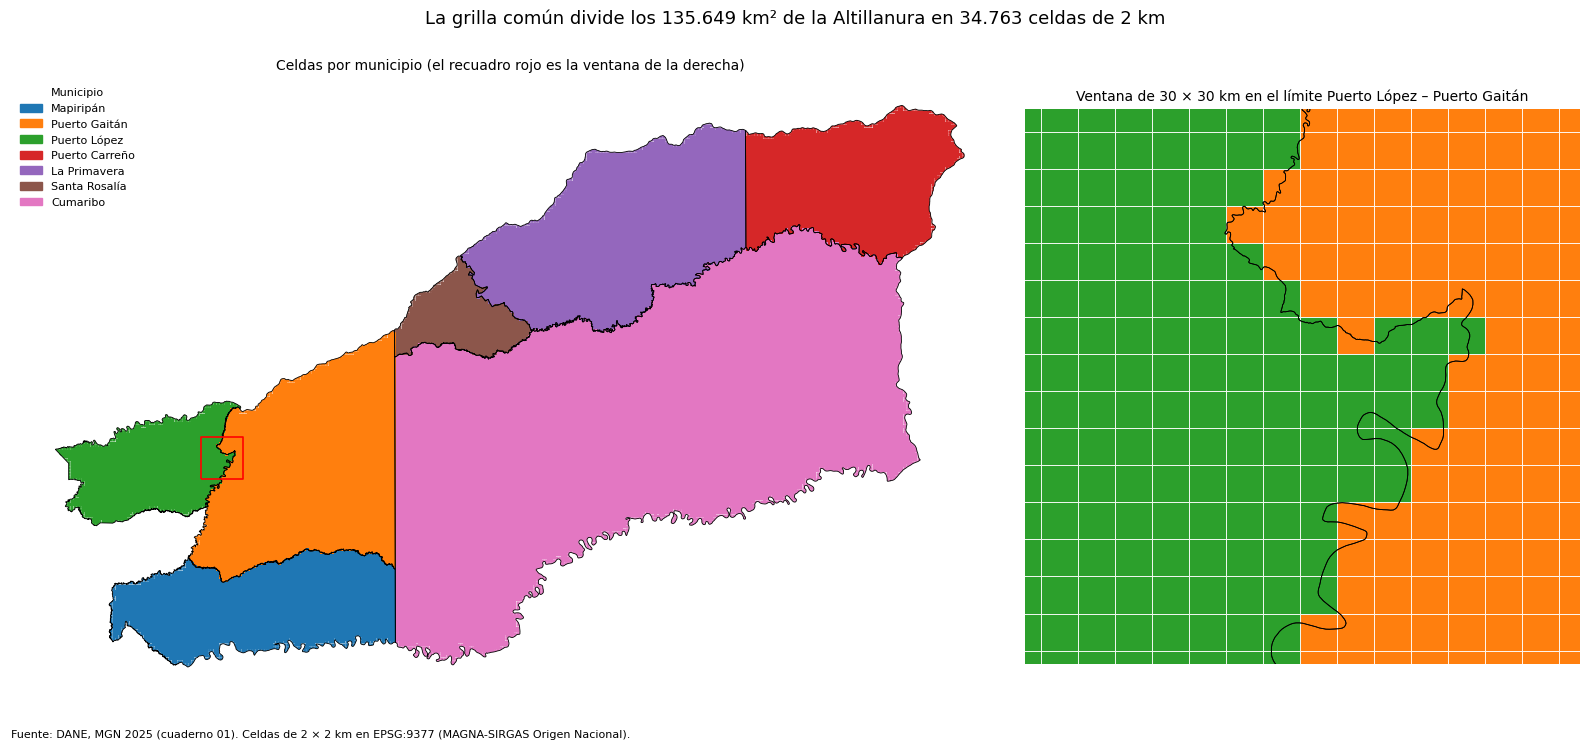

In [17]:
paleta = plt.get_cmap('tab10').colors
colores = {nombre: paleta[i] for i, nombre in enumerate(mpios['mpio_cnmbr'])}

geom_pl = mpios.loc[mpios['mpio_cdpmp'] == '50573', 'geometry'].iloc[0]
geom_pg = mpios.loc[mpios['mpio_cdpmp'] == '50568', 'geometry'].iloc[0]
limite = geom_pl.boundary.intersection(geom_pg.boundary)
centro = limite.centroid if not limite.is_empty else area_estudio.representative_point()
MEDIA_VENTANA = 15000
ventana = shapely.box(centro.x - MEDIA_VENTANA, centro.y - MEDIA_VENTANA,
                      centro.x + MEDIA_VENTANA, centro.y + MEDIA_VENTANA)
zoom = celdas[celdas.intersects(ventana)]

fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), gridspec_kw={'width_ratios': [1.8, 1]})
for nombre, color in colores.items():
    celdas[celdas['mpio_cnmbr'] == nombre].plot(ax=axes[0], color=color, linewidth=0)
    zoom[zoom['mpio_cnmbr'] == nombre].plot(ax=axes[1], color=color, edgecolor='white', linewidth=0.6)
for ax in axes:
    mpios.boundary.plot(ax=ax, color='black', linewidth=0.6)
    ax.set_axis_off()
gpd.GeoSeries([ventana], crs=9377).boundary.plot(ax=axes[0], color='red', linewidth=1.2)
axes[1].set_xlim(ventana.bounds[0], ventana.bounds[2])
axes[1].set_ylim(ventana.bounds[1], ventana.bounds[3])

axes[0].set_title('Celdas por municipio (el recuadro rojo es la ventana de la derecha)', fontsize=10)
axes[1].set_title('Ventana de 30 × 30 km en el límite Puerto López – Puerto Gaitán', fontsize=10)
axes[0].legend(handles=[Patch(color=c, label=n.title()) for n, c in colores.items()],
               loc='upper left', fontsize=8, frameon=False, title='Municipio', title_fontsize=8)

total = f'{AREA_TOTAL_KM2:,.0f}'.replace(',', '.')
n_celdas = f'{len(celdas):,}'.replace(',', '.')
fig.suptitle(f'La grilla común divide los {total} km² de la Altillanura en {n_celdas} celdas de 2 km', fontsize=13)
fig.text(0.01, 0.01, 'Fuente: DANE, MGN 2025 (cuaderno 01). Celdas de 2 × 2 km en EPSG:9377 (MAGNA-SIRGAS Origen Nacional).',
         fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(GRAFICAS, '02_grilla_2km.png'), dpi=150, bbox_inches='tight')
plt.show()

## Paso 6. Guardar la grilla
Se guarda en `datos/comunes/grilla_2km.gpkg` (capa `grilla`) y se vuelve a leer para comprobar que quedó bien escrita.

In [18]:
SALIDA = os.path.join(COMUNES, 'grilla_2km.gpkg')
if os.path.exists(SALIDA):
    os.remove(SALIDA)
celdas.to_file(SALIDA, layer='grilla', driver='GPKG')

leida = gpd.read_file(SALIDA)
assert len(leida) == len(celdas)
assert leida.crs.to_epsg() == 9377
assert leida['id_celda'].is_unique

print(f'Guardado: {SALIDA}')
print(f'{len(leida):,} celdas | CRS: {leida.crs} | {os.path.getsize(SALIDA) / 1e6:.1f} MB')
print('Columnas:', list(leida.columns))
leida.drop(columns='geometry').head()

Guardado: c:\Users\mipip\Downloads\altillanura_proyecto_\altillanura_proyecto\datos\comunes\grilla_2km.gpkg
34,763 celdas | CRS: EPSG:9377 | 11.7 MB
Columnas: ['id_celda', 'mpio_cdpmp', 'mpio_cnmbr', 'area_km2', 'frac_celda', 'x_9377', 'y_9377', 'geometry']


,id_celda,mpio_cdpmp,mpio_cnmbr,area_km2,frac_celda,x_9377,y_9377
0,x4970_y2012,50573,PUERTO LÓPEZ,0.143016,0.035754,4971825.9,2013817.4
1,x4970_y2014,50573,PUERTO LÓPEZ,0.451955,0.112989,4971653.6,2014335.3
2,x4972_y2010,50573,PUERTO LÓPEZ,0.198384,0.049596,4973795.0,2011785.0
3,x4972_y2012,50573,PUERTO LÓPEZ,2.994346,0.748586,4973180.8,2013173.3
4,x4972_y2014,50573,PUERTO LÓPEZ,1.611103,0.402776,4973102.6,2014418.3
